# Practical 2 — Instructor solutions: Can physics-informed neural networks reconstruct dynamics and identify physical parameters?

**Machine Learning for Physics 2026 - MSIAM / Ensimag**  

*Author: Filippo Masi*

Imagine observing the evolution of a nonlinear flow. You know the form of its equation, but do not necessarily know its physical parameters (e.g. the viscosity). Can a neural field reconstruct the space–time solution from physics? And can a small set of noisy velocity observations identify a coefficient that appears in the PDE?

This practical follows the viscous Burgers equation. We start with a smooth regime, then use the very same computational ingredients for an inverse problem. The final experiment asks whether a PINN trained for one flow experiment can solve another without retraining.

What you will be able to do:
- Derive a nonlinear space-time residual with mixed first- and second-order coordinate derivatives.
- Distinguish physics points, initial/boundary points and scarce noisy observations.
- Recover a positive unknown viscosity together with the neural solution field.
- Diagnose errors using solution snapshots, held-out PDE residual maps and parameter histories.
- State precisely what is (and is not) learned by a conventional PINN.

Suggestion: if debugging, begin with 300 forward / 500 inverse steps before the longer runs.


## 1. From heat conduction to nonlinear dynamics

Now the unknown field depends on position and time: $u(x,t)$ is a scalar velocity on $-1<x<1$, $0<t\le1$. It obeys

$$u_t+u\,u_x-\nu u_{xx}=0,\qquad\nu>0,$$
$$u(-1,t)=u(1,t)=0,\qquad u(x,0)=-\sin(\pi x).$$

The term $u\,u_x$ advects the signal and can sharpen gradients; viscosity $\nu u_{xx}$ smooths them. Their competition is what makes Burgers more interesting than Poisson. For the core exercise we set $\nu=0.1$ so training is feasible in class. A smaller, more challenging value is optional.

- Identify the roles of $u_t$, $u_x$ and $u_{xx}$. How many input coordinates does the network need? What is the difference between initial data at $t=0$ and spatial boundary data at $x=\pm1$? Try to write the residual without looking ahead.

The next supplied cell generates a numerical reference. It is a measuring stick for validation and, later, a source of simulated sensor readings. It is not used as labeled training data in the forward PINN. At low viscosity, reference resolution should itself be verified.

**Answer.** $u_t$ describes local time evolution, $u_x$ describes spatial changes, and $u_{xx}$ measures spatial curvature (diffusion). The network has **two inputs** $(x,t)$ and one scalar output $u_\theta$. The initial condition specifies an entire spatial profile at $t=0$, whereas each boundary condition specifies one endpoint value for all times. Without both the PDE and appropriate initial/boundary information, the physical experiment is not selected uniquely. 

In [1]:
import time
import copy
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.sparse import diags

# Reproducible setup.
torch.set_num_threads(1)
torch.set_default_dtype(torch.float32)
torch.manual_seed(29)
rng = np.random.default_rng(29)
PI = np.pi
NU_TRUE = 0.1         # smaller viscosity is optional.
FORWARD_STEPS = 3500   # During debugging, start with 300.
INVERSE_STEPS = 5000   # During debugging, start with 500.


def initial_velocity(x):
    """Known velocity field at t=0; x is a torch tensor."""
    return -torch.sin(PI * x)


### Provided numerical reference — run, do not modify

For this Burgers setup there is no comparably convenient elementary analytic solution. A numerical integrator is provided below. Treat it as a reference experiment, not a code exercise.

Observe: the initial velocity has both positive and negative regions, and its shape changes with time. Later, compare whether the PINN captures those changes rather than just matching one snapshot.

Reference array [time, position]: (51, 101)


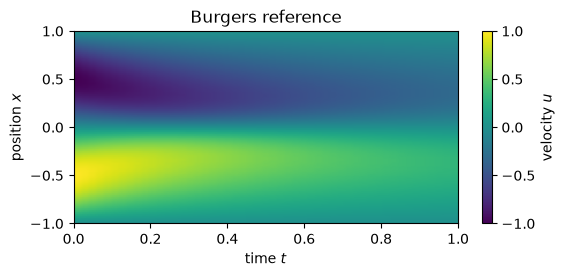

In [2]:
# PROVIDED: a numerical Burgers reference, only for checking the PINN.
# Its values are never used as labels by the forward PINN.
def burgers_reference(nu=0.1, amplitude=1.0, nx=101, nt=51, t_f=1.0):
    """Return x, t, U; U has shape [number of times, number of positions]."""
    if nu <= 0:
        raise ValueError('Viscosity must be positive.')
    if nx < 5 or nt < 2:
        raise ValueError('Reference grid must contain enough points.')

    x = np.linspace(-1.0, 1.0, nx)
    t = np.linspace(0.0, t_f, nt)
    dx = x[1] - x[0]
    # Only interior values are unknown: the two endpoints stay at zero.
    initial = -amplitude * np.sin(PI * x[1:-1])

    def evolution(_time, interior):
        u = np.r_[0.0, interior, 0.0]
        u_x = (u[2:] - u[:-2]) / (2.0 * dx)
        u_xx = (u[2:] - 2.0 * u[1:-1] + u[:-2]) / dx**2
        return -u[1:-1] * u_x + nu * u_xx

    # A tridiagonal Jacobian sparsity pattern keeps the provided BDF solver
    # efficient even on the finer grids used in optional bonus A.
    sparsity = diags([np.ones(nx-3), np.ones(nx-2), np.ones(nx-3)],
                     offsets=[-1, 0, 1], format='csr')
    result = solve_ivp(evolution, (0.0, t_f), initial, t_eval=t,
                       jac_sparsity=sparsity,
                       method='BDF', rtol=2e-7, atol=2e-9)
    if not result.success:
        raise RuntimeError('Reference integration failed: ' + result.message)
    U = np.column_stack([np.zeros(nt), result.y.T, np.zeros(nt)])
    return x, t, U

# Numerical reference for comparisons and synthetic measurements (not PINN labels).
reference_start = time.perf_counter()
x_ref, t_ref, U_ref = burgers_reference(nu=NU_TRUE)
reference_time = time.perf_counter() - reference_start
print('Reference array [time, position]:', U_ref.shape)

# Reference overview: axes are time (horizontal) and position (vertical).
fig, ax = plt.subplots(figsize=(6.2, 2.5), dpi=100)
im = ax.imshow(U_ref.T, extent=(t_ref[0], t_ref[-1], x_ref[0], x_ref[-1]),
               origin='lower', aspect='auto')
ax.set(xlabel='time $t$', ylabel='position $x$',
       title='Burgers reference')
fig.colorbar(im, ax=ax, label='velocity $u$')
plt.show()


### Plotting tools

All plotting code is embedded below, so the notebook is self-contained.

In [3]:
# Given visualization helpers for Practical 2.

def plot_burgers_snapshots(x, t, reference, prediction, init_pts, boundary_pts,
                           snapshot_times=(0.25, 0.50, 0.75)):
    """A space-time PINN field followed by three reference/PINN time slices."""
    x, t = np.asarray(x), np.asarray(t)
    reference, prediction = np.asarray(reference), np.asarray(prediction)
    vmax = max(np.abs(reference).max(), np.abs(prediction).max(), 1e-8)

    fig = plt.figure(figsize=(9.0, 4.8), constrained_layout=True)
    grid = fig.add_gridspec(2, 3)
    ax_field = fig.add_subplot(grid[0, :])

    # Transposition is needed because U is stored [time, position].
    im = ax_field.imshow(prediction.T, extent=(t[0], t[-1], x[0], x[-1]),
                         origin='lower', aspect='auto', vmin=-vmax, vmax=vmax)
    ip, bp = np.asarray(init_pts), np.asarray(boundary_pts)
    ax_field.scatter(ip[:, 1], ip[:, 0], s=10, marker='x', label='IC/BC samples')
    ax_field.scatter(bp[:, 1], bp[:, 0], s=10, marker='x')

    for selected_t in snapshot_times:
        index = np.argmin(np.abs(t - selected_t))
        ax_field.axvline(t[index], linestyle=':', linewidth=1)
    ax_field.set(title='PINN space-time field', xlabel='time $t$', ylabel='position $x$')
    ax_field.legend(fontsize=8, loc='lower right')
    fig.colorbar(im, ax=ax_field, label='velocity $u$', shrink=0.85)

    for j, selected_t in enumerate(snapshot_times):
        index = np.argmin(np.abs(t - selected_t))
        ax = fig.add_subplot(grid[1, j])
        ax.plot(x, reference[index], label='Reference')
        ax.plot(x, prediction[index], '--', label='PINN')
        ax.set(title=f'({"bcd"[j]}) $t={t[index]:.2f}$',
               xlabel='position $x$', ylabel='velocity $u$')
        ax.set_ylim(-1.15 * vmax, 1.15 * vmax)
        if j == 0:
            ax.legend(fontsize=8)
    plt.show()


def residual_map(model, residual_fn, nu, x, t, batch_size=512):
    """Evaluate the differentiable PDE residual on a held-out space-time grid."""
    xx, tt = np.meshgrid(np.asarray(x), np.asarray(t), indexing='xy')
    coords = np.column_stack((xx.ravel(), tt.ravel())).astype(np.float32)
    pieces = []

    # Coordinate derivatives require an autograd graph, so no torch.no_grad().
    for k in range(0, len(coords), batch_size):
        xt = torch.tensor(coords[k:k + batch_size], dtype=torch.float32)
        r = residual_fn(model, xt, nu)
        pieces.append(r.detach().cpu().numpy().ravel())
    return np.concatenate(pieces).reshape(len(t), len(x))


def plot_burgers_diagnostics(x, t, reference, prediction, residual,
                             history, collocation_example):
    """Compare field accuracy with the PDE residual away from training points."""
    from matplotlib.colors import LogNorm

    x, t = np.asarray(x), np.asarray(t)
    reference, prediction = np.asarray(reference), np.asarray(prediction)
    history = np.asarray(history)
    vmax = max(np.abs(reference).max(), np.abs(prediction).max(), 1e-8)
    extent = (x[0], x[-1], t[0], t[-1])

    fig = plt.figure(figsize=(8.6, 5.3), constrained_layout=True)
    grid = fig.add_gridspec(2, 3)
    top_axes = [fig.add_subplot(grid[0, j]) for j in range(3)]
    ax_res = fig.add_subplot(grid[1, :2])
    ax_loss = fig.add_subplot(grid[1, 2])

    for ax, field, title, shared_limits in zip(
            top_axes,
            (reference, prediction, np.abs(prediction - reference)),
            ('numerical reference', 'PINN prediction', 'absolute error'),
            (True, True, False)):
        # Default imshow colormap, with comparable value ranges for state fields.
        im = ax.imshow(field, extent=extent, origin='lower', aspect='auto',
                       **({'vmin': -vmax, 'vmax': vmax} if shared_limits else {}))
        ax.set(title=title, xlabel='$x$', ylabel='$t$')
        fig.colorbar(im, ax=ax, fraction=0.045, pad=0.03)

    # Logarithmic scaling reveals localized residual peaks.
    absolute_r = np.maximum(np.abs(residual), 1e-10)
    lower = max(1e-8, float(np.percentile(absolute_r, 3)) / 2)
    upper = max(20 * lower, float(absolute_r.max()))
    im = ax_res.imshow(absolute_r, extent=extent, origin='lower', aspect='auto',
                       norm=LogNorm(vmin=lower, vmax=upper))
    xy = np.asarray(collocation_example)
    ax_res.scatter(xy[:, 0], xy[:, 1], s=8, marker='x',
                   label='example collocation sampling')
    ax_res.set(title='held-out absolute PDE residual (log)',
               xlabel='$x$', ylabel='$t$')
    ax_res.legend(fontsize=8)
    fig.colorbar(im, ax=ax_res, label='$|r_\\theta|$')

    # The training set is resampled. The validation coordinates remain fixed.
    ax_loss.semilogy(history[:, 0], np.maximum(history[:, 2], 1e-13),
                     label='Training batch')
    if history.shape[1] >= 6:
        ax_loss.semilogy(history[:, 0], np.maximum(history[:, 5], 1e-13),
                         label='held-out points')
    ax_loss.set(title='PDE loss', xlabel='Adam iteration', ylabel='residual MSE')
    ax_loss.legend(fontsize=8)
    plt.show()


def plot_inverse_report(history, true_viscosity, measurements):
    """Show where data are observed, parameter evolution, and inverse losses."""
    history = np.asarray(history)
    observations = np.asarray(measurements)
    fig, axes = plt.subplots(1, 3, figsize=(9.0, 2.7), constrained_layout=True)

    dots = axes[0].scatter(observations[:, 0], observations[:, 1],
                           c=observations[:, 2], s=24)
    axes[0].set(title='observations', xlabel='$x$', ylabel='$t$')
    fig.colorbar(dots, ax=axes[0], label='observed $u$')

    axes[1].plot(history[:, 0], history[:, 1], label='Estimated $\\nu$')
    axes[1].axhline(true_viscosity, linestyle='--', label='True $\\nu$')
    axes[1].set(title='viscosity inference', xlabel='Adam iteration', ylabel='$\\nu$')
    axes[1].legend(fontsize=8)

    for index, label in ((2, 'PDE'), (3, 'Initial'), (4, 'Boundary'), (5, 'Sensors')):
        axes[2].semilogy(history[:, 0], np.maximum(history[:, index], 1e-13),
                         label=label)
    axes[2].set(title='inverse PINN losses', xlabel='Adam iteration', ylabel='MSE')
    axes[2].legend(fontsize=8)
    plt.show()


def plot_transfer(x, t, changed_reference, old_prediction):
    """An unchanged single-instance PINN cannot respond to an unprovided new IC."""
    x, t = np.asarray(x), np.asarray(t)
    truth, old = np.asarray(changed_reference), np.asarray(old_prediction)
    vmax = max(np.abs(truth).max(), np.abs(old).max(), 1e-8)
    extent = (x[0], x[-1], t[0], t[-1])
    fig, axes = plt.subplots(2, 2, figsize=(7.7, 4.7), constrained_layout=True)

    for ax, field, title in zip(axes[0], (truth, old),
                                ('new IVP: reference', 'PINN')):
        im = ax.imshow(field, extent=extent, origin='lower', aspect='auto',
                       vmin=-vmax, vmax=vmax)
        ax.set(title=title, xlabel='$x$', ylabel='$t$')
        fig.colorbar(im, ax=ax, label='velocity $u$')

    for ax, i, title in zip(axes[1], (0, -1), ('(c) Initial state', '(d) Final state')):
        ax.plot(x, truth[i], label='New IVP')
        ax.plot(x, old[i], '--', label='Old PINN')
        ax.set(title=title, xlabel='position $x$', ylabel='velocity $u$')
        ax.legend(fontsize=8)
    plt.show()


## Exercises 1–2 — Turn Burgers' equation into a trainable loss

A spatio-temporal neural network $u_\theta(x,t)=N_\theta([x,t])$ should respect the governing dynamics and the data that select the desired solution. The physics-based residual is

$$r_\theta(x,t)=u_{\theta,t}+u_\theta u_{\theta,x}-\nu u_{\theta,xx}.$$

We evaluate three different physical statements on three different sets of points:

$$L_f=\operatorname{mean}_{(x,t)\in\mathcal D_f}(r_\theta^2),\quad
L_0=\operatorname{mean}_{x\in\mathcal D_0}\big(u_\theta(x,0)+\sin(\pi x)\big)^2,\quad
L_b=\operatorname{mean}_{(\pm1,t)\in\mathcal D_b}u_\theta(\pm1,t)^2,$$
$$L=L_f+10L_0+10L_b.$$

**Exercise 1 — Derivatives and nonlinearity:** implement `burgers_residual`. Note: `grad(u, xt)` returns both derivatives of the two-column input `xt`: column 0 is $x$, column 1 is $t$. Differentiate the extracted $u_x$ again to obtain $u_{xx}$. A supplied polynomial field with known derivatives tests not only tensor dimensions but the actual PDE formula.

**Exercise 2 — Build the forward objective:** Complete `forward_losses`, keeping PDE, initial and boundary terms separate. The optimizer loop is supplied: you wrote one in Practical 1. There are no numerical reference labels in this forward objective.

- If you removed $L_0$, what information would be missing? If you kept only $L_0$, would you determine the future evolution? After training: inspect whether all three losses decrease. A small weighted total can hide an uneven compromise between constraints.


**Answer.** Automatic differentiation computes spatial and temporal derivatives of the *same neural field*: the nonlinear term is $u_\theta u_{\theta,x}$, not $(u_\theta)^2$ or $u_{\theta,x}^2$. Its second spatial derivative must use the $x$ column of the derivative of $u_x$. The collocation, initial and boundary sets have different geometric roles. Without $L_0$ the initial state of the experiment is not selected. Without imposing the PDE residual, fitting $t=0$ cannot determine evolution at $t>0$. Removing $L_b$ also weakens uniqueness, since the endpoint conditions are no longer enforced. The three terms should be inspected separately because the weighted sum can hide imbalances.


In [4]:
def make_burgers_net(width=32):
    """A small smooth MLP: two inputs (x,t), one velocity output."""
    return nn.Sequential(
        nn.Linear(2, width), nn.Tanh(),
        nn.Linear(width, width), nn.Tanh(),
        nn.Linear(width, 1),
    )


def grad(y, x):
    """Derivative of batched scalar outputs with respect to batched coordinates."""
    return torch.autograd.grad(y, x, torch.ones_like(y), create_graph=True)[0]


def burgers_residual(model, xt, nu):
    """Return r(x,t) = u_t + u*u_x - nu*u_xx."""
    xt = xt.detach().clone().requires_grad_(True)
    u = model(xt)
    deriv = grad(u, xt)
    u_x, u_t = deriv[:, 0:1], deriv[:, 1:2]
    u_xx = grad(u_x, xt)[:, 0:1]
    return u_t + u * u_x - nu * u_xx

# A mathematical test, not just a tensor-shape check.
# For u(x,t)=x^2 (t+1), we know u_t=x^2, u_x=2x(t+1), u_xx=2(t+1).
class PolynomialField(nn.Module):
    def forward(self, xt):
        return xt[:, :1]**2 * (xt[:, 1:2] + 1.0)

probe = torch.rand(11, 2)
x_probe, t_probe = probe[:, :1], probe[:, 1:2]
u_probe = x_probe**2 * (t_probe + 1.0)
r_expected = x_probe**2 + u_probe * (2.0 * x_probe * (t_probe + 1.0)) - NU_TRUE * (2.0 * (t_probe + 1.0))
r_computed = burgers_residual(PolynomialField(), probe, NU_TRUE)
assert r_computed.shape == (11, 1)
assert torch.allclose(r_computed, r_expected, atol=2e-5)
print('Burgers automatic-differentiation and residual checks passed.')


Burgers automatic-differentiation and residual checks passed.


In [5]:
def sample_sets(n_f=256, n_i=80, n_b=80):
    """Fresh PDE, initial-condition, and boundary-condition samples."""
    # Collocation points: x in [-1,1], t in [0,1].
    xf = 2*torch.rand(n_f, 1)-1
    tf = torch.rand(n_f, 1)
    xt_f = torch.cat([xf, tf], dim=1)
    # Initial points all have t=0.
    xi = 2*torch.rand(n_i, 1)-1
    xt_i = torch.cat([xi, torch.zeros_like(xi)], dim=1)
    # Boundary points are distributed on BOTH x=-1 and x=1.
    xb = torch.where(torch.rand(n_b, 1)>0.5, 1., -1.)
    tb = torch.rand(n_b, 1)
    xt_b = torch.cat([xb, tb], dim=1)
    return xt_f, xt_i, xt_b


def forward_losses(model, nu=NU_TRUE, n_f=256, fixed_f=None):
    """PDE residual plus initial- and boundary-condition losses."""
    xt_f, xt_i, xt_b = sample_sets(n_f=n_f)
    if fixed_f is not None:
        # Reuse identical PDE coordinates (bonus D). IC/BC samples still vary.
        xt_f = fixed_f
    l_f = burgers_residual(model, xt_f, nu).square().mean()
    l_i = (model(xt_i) - initial_velocity(xt_i[:, :1])).square().mean()
    l_b = model(xt_b).square().mean()
    return l_f + 10*l_i + 10*l_b, (l_f, l_i, l_b)


def train_burgers(model, steps=FORWARD_STEPS, lr=2e-3, nu=NU_TRUE,
                  n_f=256, fixed_f=None):
    """Fit one Burgers solution using only the PDE, IC and BC."""
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    # A fixed, unseen validation set tests the PDE between training batches.
    # A separate generator avoids changing the stochastic training sequence.
    val_rng = torch.Generator().manual_seed(2903)
    val_x = 2 * torch.rand(300, 1, generator=val_rng) - 1
    val_t = torch.rand(300, 1, generator=val_rng)
    validation_xt = torch.cat([val_x, val_t], dim=1)
    start = time.perf_counter()
    for step in range(steps):
        opt.zero_grad()
        total, parts = forward_losses(model, nu=nu, n_f=n_f, fixed_f=fixed_f)
        total.backward()
        opt.step()
        if step % 20 == 0:
            # Do not use no_grad(): residuals involve coordinate derivatives.
            # Training PDE MSE uses the current resampled optimization batch.
            # Validation PDE MSE uses the same held-out coordinates each time.
            val_pde = burgers_residual(model, validation_xt, nu).square().mean()
            history.append([step, total.item(), *[part.item() for part in parts],
                            val_pde.detach().item()])
    return np.array(history), time.perf_counter()-start

forward_model = make_burgers_net()
# Save the untrained weights for a fair matched-initialization bonus comparison.
forward_initial_weights = copy.deepcopy(forward_model.state_dict())
forward_hist, forward_time = train_burgers(forward_model)
print(f'Forward PINN trained in {forward_time:.1f} s, final weighted loss {forward_hist[-1,1]:.2e}')

Forward PINN trained in 4.3 s, final weighted loss 3.23e-03


## Exercise 3 — Interpret the solution

A low training loss is not the final claim. We want to know what happens outside the sampled points, whether the shape of the flow is reproduced at several times, and where the residual is concentrated.

The next code cell evaluates the PINN on a reference grid that was not used as training labels. It reports (i) relative state error over space–time, (ii) final-time relative state error, and (iii) root-mean-squared (RMS) PDE residual on unseen points.

- Your task:
1. Examine the space-time solution + three snapshots: at $t=0.25,0.50,0.75$, where does the prediction diverge from the reference? Look especially around steepening gradients.
2. Examine the reference solution, the predictions, error, residual + training/held-out curves: Does the largest error coincide with the largest PDE residual? Can an average PDE loss hide a localized failure?

**Domain check:** Our forward PINN was trained for $0\le t\le1$. Reference fields, predictions and sensors must use matching coordinates. A prediction at $t>1$ is a *time extrapolation* experiment, not an ordinary test on the training domain.


**Answer.** The relative state error compares two fields on identical $(x,t)$ coordinates. A held-out residual tests whether the PDE is approximately satisfied away from optimization samples; it is not itself the state error. Examine the printed positions of the largest pointwise state error and PDE residual below: these locations need not coincide, since error propagation and boundary/initial mismatch also matter. Inspect the numerical reference around sharpening gradients instead of judging a PINN by its final total training loss. Validation past $t=1$ requires explicitly evaluating the network and reference on a new common grid; it is not measured in the main experiment.


Forward: rel L2 all grid=1.817e-02, t=1=1.559e-02, fresh rms PDE residual=4.48e-02


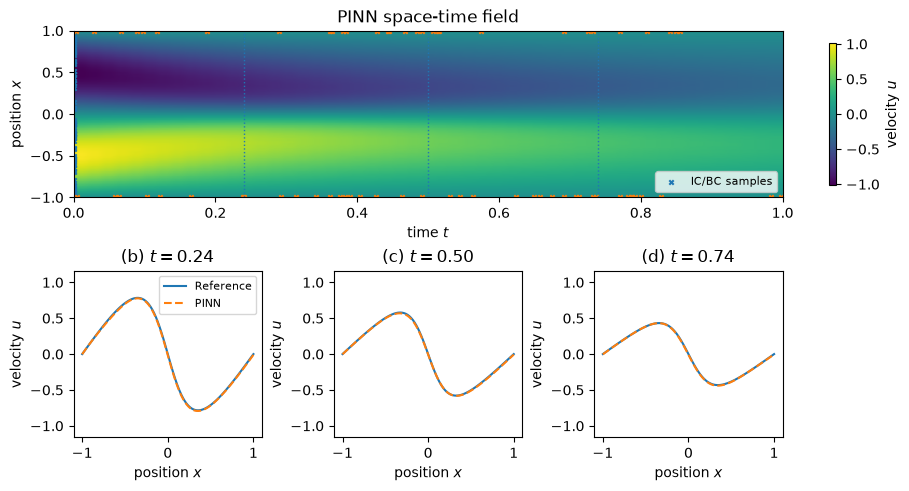

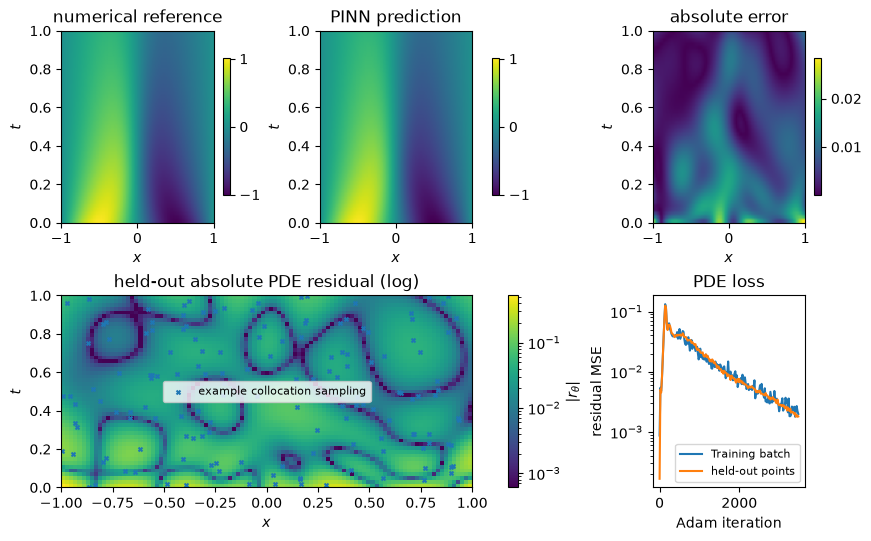

Largest pointwise state error: 2.837e-02 at (x,t)=(1.00, 0.00)
Largest |PDE residual| on grid: 5.264e-01 at (x,t)=(-1.00, 0.00)


In [6]:
def predict_on_grid(model, x, t):
    """Evaluate the neural field on the (time, position) reference grid."""
    tt, xx = np.meshgrid(t, x, indexing='ij')
    xt = torch.tensor(np.c_[xx.ravel(), tt.ravel()], dtype=torch.float32)
    with torch.no_grad():
        return model(xt).numpy().reshape(len(t), len(x))


def relative_error(a, ref):
    """Discrete normalized Euclidean error (same sampling for both arrays)."""
    return np.linalg.norm(a-ref) / np.linalg.norm(ref)

U_pinn = predict_on_grid(forward_model, x_ref, t_ref)
fwd_err = relative_error(U_pinn, U_ref)
last_err = relative_error(U_pinn[-1], U_ref[-1])
validation_points = torch.cat([2*torch.rand(500,1)-1, torch.rand(500,1)], dim=1)
fresh_res = burgers_residual(forward_model, validation_points, NU_TRUE).square().mean().sqrt().detach().item()
print(f'Forward: rel L2 all grid={fwd_err:.3e}, t=1={last_err:.3e}, fresh rms PDE residual={fresh_res:.2e}')


# Keep the original reference grid t in [0,1] for aligned comparison.

figure_rng = np.random.default_rng(164)
init_x = 2*figure_rng.random(60) - 1
initial_example = np.c_[init_x, np.zeros_like(init_x)]
boundary_t = figure_rng.random(70)
boundary_x = figure_rng.choice([-1.0, 1.0], 70)
boundary_example = np.c_[boundary_x, boundary_t]
plot_burgers_snapshots(
    x_ref, t_ref, U_ref, U_pinn, initial_example, boundary_example,snapshot_times=(0.25, 0.50, 0.75)
)

# The grid is NOT used to optimize the network, so it tests residual generalization.
r_holdout = residual_map(forward_model, burgers_residual, NU_TRUE, x_ref, t_ref)
collocation_example = np.c_[2*figure_rng.random(150)-1, 1*figure_rng.random(150)]
plot_burgers_diagnostics(
    x_ref, t_ref, U_ref, U_pinn, r_holdout, forward_hist,
    collocation_example,
)


# Locate errors and residual hotspots instead of guessing from the color scale.
abs_state_error = np.abs(U_pinn - U_ref)
peak_index = np.unravel_index(abs_state_error.argmax(), abs_state_error.shape)
peak_res_index = np.unravel_index(np.abs(r_holdout).argmax(), r_holdout.shape)
print(f'Largest pointwise state error: {abs_state_error[peak_index]:.3e} '
      f'at (x,t)=({x_ref[peak_index[1]]:.2f}, {t_ref[peak_index[0]]:.2f})')
print(f'Largest |PDE residual| on grid: {abs(r_holdout[peak_res_index]):.3e} '
      f'at (x,t)=({x_ref[peak_res_index[1]]:.2f}, {t_ref[peak_res_index[0]]:.2f})')


## Exercise 4 — Inverse PINN: estimate a viscosity you cannot directly measure

Suppose the equation and imposed conditions are known, but $\nu$ is not. A few noisy velocity sensors report $y_j\approx u(x_j,t_j)$ at scattered coordinates. Now the learning problem is genuinely an inverse problem: we need the physical field and a physical coefficient.

Instead of optimizing $\nu$ directly, define an unconstrained trainable scalar $\eta$ and set

$$\nu=\exp(\eta)>0.$$

Add a data term to the earlier physics loss:

$$L_d=\frac{1}{N_d}\sum_j\big(u_\theta(x_j,t_j)-y_j\big)^2,\qquad
L_{\mathrm{inv}}=L_f+10L_0+10L_b+30L_d.$$

- Inspect the supplied sensor positions. Complete the positive-viscosity property and the loss contributions in `inverse_losses`. The joint optimizer (updating both the NN weights $\theta$ and $\eta$) is provided.

- Why does the PDE alone fail to determine $\nu$? Why are multiple sensor times useful? Why should $\nu$ be constrained to remain positive? Why is a fresh network initialization important for an honest inverse test? 

- Plot the estimated viscosity over iterations, and quote both the recovered coefficient and the remaining PDE/data losses. If the data loss is small but $\nu$ is biased, think of noise, model flexibility, sensor locations and loss weights before changing the architecture.

**Answer.** For every admissible viscosity, the Burgers initial-boundary-value problem defines a different solution; the PDE alone does not say which $\nu$ generated the experiment. Sensor observations supply the missing information. Observations spread over time capture the cumulative effect of diffusion and generally improve parameter sensitivity, while early-time measurements can be less informative. $\exp(\eta)$ enforces the physical requirement $\nu>0$ without projection. A *fresh* neural network is essential: warm-starting from a field trained with the true viscosity leaks privileged information into what is supposed to be a blind inverse test. One fitted parameter, even with small data loss, is not a confidence interval: uncertainty also depends on noise, observation geometry, optimizer restarts, and model discrepancy.


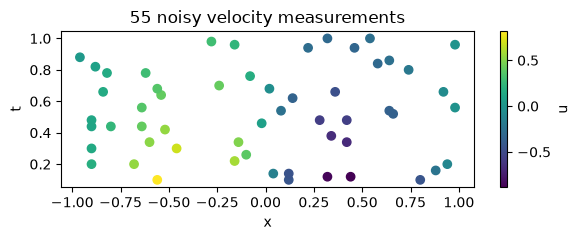

In [7]:
# Reproducible, sparse observations at grid points away from t=0.
# The provided reference is the "laboratory" generating measurements.
sensor_t_idx = rng.integers(5, len(t_ref), size=55)
sensor_x_idx = rng.integers(1, len(x_ref)-1, size=55)
sensor_xt_np = np.c_[x_ref[sensor_x_idx], t_ref[sensor_t_idx]]
noise_std = 0.005
measurements_np = U_ref[sensor_t_idx, sensor_x_idx] + rng.normal(0, noise_std, size=55)
sensor_xt = torch.tensor(sensor_xt_np, dtype=torch.float32)
sensor_y = torch.tensor(measurements_np[:, None], dtype=torch.float32)

plt.figure(figsize=(6, 2.5))
plt.scatter(sensor_xt_np[:,0], sensor_xt_np[:,1], c=measurements_np, )
plt.xlabel('x'); plt.ylabel('t'); plt.title('55 noisy velocity measurements'); plt.colorbar(label='u')
plt.tight_layout(); plt.show()

Estimated nu=0.0996; true nu=0.1000; inverse time=6.8s
Final inverse losses (PDE, initial, boundary, sensors): ['3.439e-03', '9.476e-05', '2.369e-05', '5.016e-05']


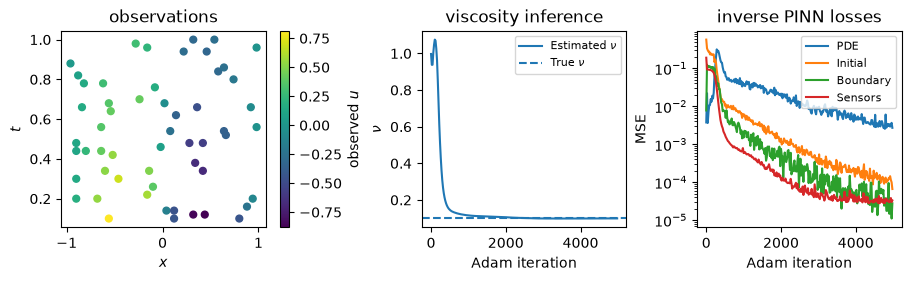

Relative viscosity error: 0.41% (one noise/seed realization).


In [8]:
class InverseBurgers(nn.Module):
    """Jointly learn the velocity field and a positive viscosity."""
    def __init__(self, warm_start=None, nu_initial=0.18):
        super().__init__()
        self.net = copy.deepcopy(warm_start) if warm_start is not None else make_burgers_net()
        self.log_nu = nn.Parameter(torch.tensor(float(np.log(nu_initial))))

    @property
    def nu(self):
        # exp parameterization guarantees that the physical coefficient is positive.
        return torch.exp(self.log_nu)

    def forward(self, xt):
        return self.net(xt)


def inverse_losses(model, data_xt=sensor_xt, data_y=sensor_y):
    """Physics + IC + BC + measurements (all evaluated separately)."""
    xt_f, xt_i, xt_b = sample_sets()
    l_f = burgers_residual(model, xt_f, model.nu).square().mean()
    l_i = (model(xt_i) - initial_velocity(xt_i[:, :1])).square().mean()
    l_b = model(xt_b).square().mean()
    l_d = (model(data_xt) - data_y).square().mean()
    return l_f + 10*l_i + 10*l_b + 30*l_d, (l_f, l_i, l_b, l_d)


def fit_viscosity(model, steps=INVERSE_STEPS, data_xt=sensor_xt, data_y=sensor_y):
    """Jointly fit a neural state and an unknown positive viscosity."""
    opt = torch.optim.Adam([
        {'params': model.net.parameters(), 'lr': 1e-3},
        {'params': [model.log_nu], 'lr': 3e-3},
    ])
    history = []
    start = time.perf_counter()
    for k in range(steps):
        opt.zero_grad()
        loss, components = inverse_losses(model, data_xt=data_xt, data_y=data_y)
        loss.backward()
        opt.step()
        if k % 20 == 0:
            history.append([k, model.nu.detach().item(), *[q.detach().item() for q in components]])
    return np.array(history), time.perf_counter()-start

# Start from a fresh network: unlike a warm start, this inference does not
# secretly import a solution already trained with the true viscosity.
inverse_model = InverseBurgers(warm_start=None, nu_initial=1.0)
inverse_hist, inverse_time = fit_viscosity(inverse_model)
print(f'Estimated nu={inverse_model.nu.item():.4f}; true nu={NU_TRUE:.4f}; inverse time={inverse_time:.1f}s')
# Re-evaluate the separate losses on a new batch: no rounding of the data term.
_, inverse_components = inverse_losses(inverse_model)
print('Final inverse losses (PDE, initial, boundary, sensors):',
      [f'{value.detach().item():.3e}' for value in inverse_components])

# Sensors, identified physics parameter, and *separate* loss terms in one figure.
plot_inverse_report(
    inverse_hist, NU_TRUE, np.c_[sensor_xt_np, measurements_np],
)

nu_hat = float(inverse_model.nu.detach())
nu_rel_error = abs(nu_hat - NU_TRUE)/NU_TRUE
print(f'Relative viscosity error: {100*nu_rel_error:.2f}% (one noise/seed realization).')


## Exercise 5 — Can one PINN solve a different experiment?

Your forward model was trained for one specific experiment: viscosity $\nu=0.1$ and initial velocity $u_0(x)=-\sin(\pi x)$. Consider a new experiment at the same viscosity but with different initial conditions

$$u_0^{\mathrm{new}}(x)=-0.5\sin(\pi x).$$

- If the neural network takes only $(x,t)$ as input, how could it know that the initial condition has changed? Should its output at $t=0$ change merely because we compare it with a different reference problem?
- The supplied cell computes the new reference and evaluates the originally-trained PINN. Compare the error for the old and new problems, including at the initial time.
- Explain the result: this is a task mismatch for a single-instance PINN. Retraining can solve the new problem, but doing that for thousands of inputs is expensive. A neural operator could be instead a viable option, learning

$$\mathcal G:\ u_0(\cdot)\longmapsto u(\cdot,\cdot),$$

from a family of training problems.

**Answer.** The input pair $(x,t)$ contains no description of the new initial condition. Therefore the *unchanged* network predicts exactly the same output for a given $(x,t)$ regardless of which reference experiment it is compared with. The discrepancy is a task mismatch, not evidence that every PINN fails on nonlinear PDEs. Retraining a PINN or training a conditional PINN for a restricted family is possible. Operator learning instead aims to approximate an input-function-to-solution map $\mathcal G:u_0(\cdot)\mapsto u(\cdot,\cdot)$ across a distribution of problems. Distinguish in-family interpolation from generalizing to arbitrary function-valued initial data.


Unchanged PINN against new IVP: rel L2=0.945; t=0 rel error=1.002
Original IVP PINN error: 0.018


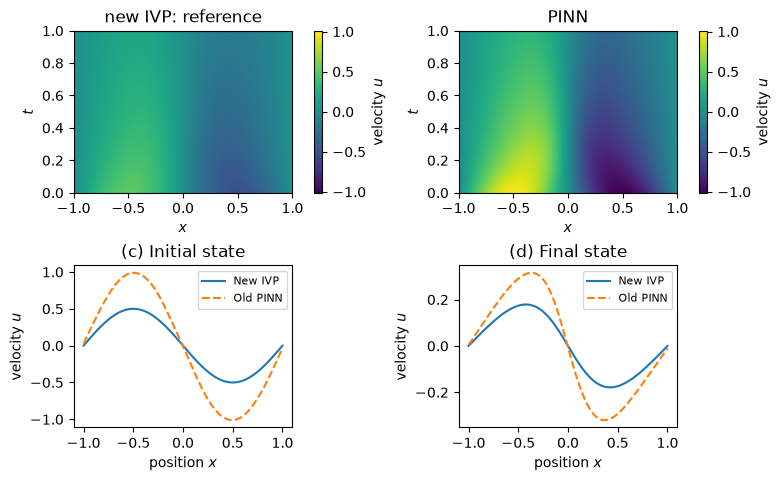

In [9]:
x_new, t_new, U_new = burgers_reference(nu=NU_TRUE, amplitude=0.5)
# The PINN has not seen the new initial-condition amplitude.
U_old_pinn = predict_on_grid(forward_model, x_new, t_new)
new_problem_error = relative_error(U_old_pinn, U_new)
new_initial_error = relative_error(U_old_pinn[0], U_new[0])
print(f'Unchanged PINN against new IVP: rel L2={new_problem_error:.3f}; t=0 rel error={new_initial_error:.3f}')
print(f'Original IVP PINN error: {fwd_err:.3f}')
plot_transfer(
    x_new, t_new, U_new, U_old_pinn,
)

## Bonus exercises

Each extension asks a new scientific question.

Change one ingredient, record the relevant metrics, and avoid conclusions from one attractive plot.

**A -** Harder physics: can the PINN capture a steep gradient? Decrease viscosity toward $\nu=0.01/\pi$, as in the early Burgers PINN demonstrations. Keep model size and training budget fixed and compare state error, localized residual, and time snapshots.

**B -** Do sensors actually identify viscosity? Use fewer sensors, concentrate them near $t=0$, or increase noise. Restart the inverse PINN from scratch. Compare the inferred parameter and remaining data/physics mismatch. Caution: a network pre-trained at the correct viscosity is not a blind inverse test.

**C -** A parameterized solution family is not yet a general operator. Train $u_\theta(x,t,a)$ over initial conditions $u_0(x;a)=-a\sin(\pi x)$ with $a\in[0.5,1.5]$. Hold out a value of $a$. Can the conditional PINN transfer? Why does mapping arbitrary functions to solutions require a richer input representation than one scalar amplitude?

**D -** Fixed collocation and residual generalization. Decrease the number of PDE points and keep their coordinates fixed: compare PDE loss on these training coordinates with a dense unseen residual map. Then restore random resampling. Does the small-sample residual sometimes look deceptively good?

**E -** Time extrapolation: evaluate the *unchanged* forward PINN at $t=1.25$ and $t=1.5$, against a correctly recomputed extended-time reference. Explain why this is a different question from the in-domain validation in Exercise 3.


### Worked bonus investigations — reproducible experiments

These extensions go beyond the required 90-minute core. Each cell uses a fresh network (never reuses a model already fit to the true viscosity), prints numerical diagnostics, and includes a short interpretation. The conclusions are empirical and budget-dependent: a single random seed or one numerical reference does not establish a universal ranking. See the recommendations at the end for more rigorous replication.

#### Bonus A — Harder physics: smaller viscosity

**Hypothesis.** Reducing $\nu$ from $0.1$ toward $0.01/\pi$ produces steeper gradients, which are more difficult for a fixed-size smooth neural network to approximate. Keep the network architecture, optimizer and number of steps unchanged, and compare the relative state error, time snapshots and residual hotspots. Because the problem becomes less diffusive, check that the reference solver is reasonably grid-resolved before interpreting the result.

The plotted residual includes the initial-time line; distinguish peaks on that line from the interior steep-gradient region.


Low-viscosity reference grid discrepancy: 2.735e-03
ν=0.1: state rel error 1.817e-02; ν=0.00318: 3.504e-01, held-out residual RMS 4.302e-01


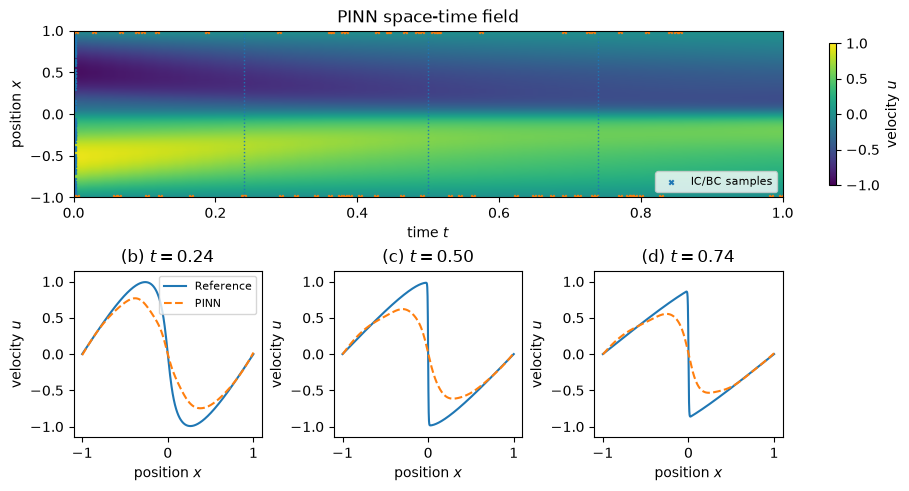

Low-ν residual hotspot (x,t)= (np.float64(0.347), np.float64(0.0)) max residual= 1.269


In [10]:
# A: new physical instance; do not modify the ν=0.1 baseline.
nu_low = 0.01 / np.pi
x_low, t_low, U_low = burgers_reference(nu=nu_low, nx=601, nt=51)

# Sanity check: a more refined reference should be close on the coarser points.
x_low_fine, t_low_fine, U_low_fine = burgers_reference(nu=nu_low, nx=1201, nt=51)
ref_grid_disagreement = relative_error(U_low_fine[:, ::2], U_low)
print(f'Low-viscosity reference grid discrepancy: {ref_grid_disagreement:.3e}')

# Reuse identical *initial weights*, not the already-trained ν=0.1 model.
low_model = make_burgers_net()
low_model.load_state_dict(copy.deepcopy(forward_initial_weights))
low_hist, low_time = train_burgers(low_model, steps=FORWARD_STEPS, nu=nu_low)
U_low_pinn = predict_on_grid(low_model, x_low, t_low)
low_error = relative_error(U_low_pinn, U_low)
low_res_map = residual_map(low_model, burgers_residual, nu_low, x_low, t_low)
low_res_rms = np.sqrt(np.mean(low_res_map**2))
print(f'ν=0.1: state rel error {fwd_err:.3e}; ν={nu_low:.5f}: '
      f'{low_error:.3e}, held-out residual RMS {low_res_rms:.3e}')

# Publication-inspired presentation of the new field, using the SAME plotting helper.
plot_burgers_snapshots(x_low, t_low, U_low, U_low_pinn,
                       initial_example, boundary_example,
                       snapshot_times=(0.25, 0.50, 0.75))

# Where is the largest low-viscosity residual?
low_peak = np.unravel_index(np.abs(low_res_map).argmax(), low_res_map.shape)
print('Low-ν residual hotspot (x,t)=',
      (round(x_low[low_peak[1]], 3), round(t_low[low_peak[0]], 3)),
      'max residual=', round(float(abs(low_res_map[low_peak])), 3))

**Interpretation.** With smaller viscosity, Burgers transports the initial field into sharper structures while diffusion smooths it less. When the same architecture and training budget perform worse, plausible causes include spectral bias, insufficient sampling near steep gradients, and difficult optimization—not a loss of mathematical validity of the PDE. The printed reference-grid discrepancy checks only numerical consistency at the tested resolution; it is not proof of exactness.

#### Bonus B — Can sparse early-time sensors identify viscosity?

**Hypothesis.** Observations confined to early times should be less informative about diffusion accumulated over the evolution, especially when they are noisy. We create an intentionally difficult experiment with only eight early measurements and stronger measurement noise. We compare this with the original 55-sensor result, keeping the same physical equation and initial/boundary conditions. This changes *both* number/timing and noise, so it is a stress test, not a controlled attribution of the change to one factor. A rigorous follow-up would vary these effects separately.

Original: 55 sensors, ν_hat=0.0996, |error|=0.0004
Difficult: 8 early/noisy sensors, ν_hat=0.1044, |error|=0.0044
Difficult-case final losses [PDE, IC, BC, sensors]: [0.003096, 0.000177, 3.1e-05, 3.3e-05]


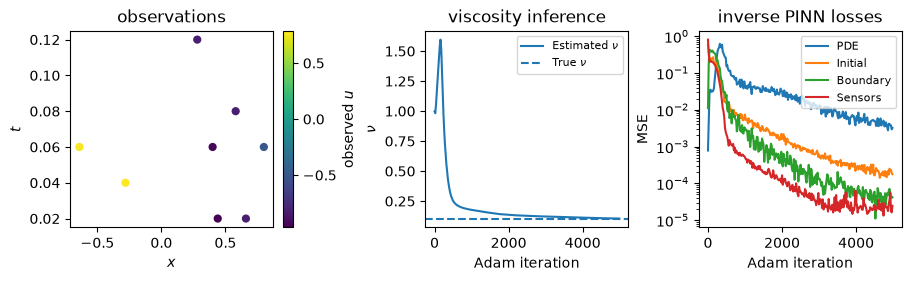

In [11]:
# B: blind inverse identification from eight early, noisy observations.
# Reproducible sensor positions on the same reference grid t in [0,1].
b_rng = np.random.default_rng(2026)
nb = 8
b_time_idx = b_rng.integers(1, 7, size=nb)   # t in [0.02,0.12]
b_space_idx = b_rng.integers(1, len(x_ref)-1, size=nb)
b_xt_np = np.c_[x_ref[b_space_idx], t_ref[b_time_idx]]
b_y_np = U_ref[b_time_idx, b_space_idx] + b_rng.normal(0.0, 0.03, size=nb)
b_xt = torch.tensor(b_xt_np, dtype=torch.float32)
b_y = torch.tensor(b_y_np[:, None], dtype=torch.float32)

torch.manual_seed(48)
b_inv_model = InverseBurgers(warm_start=None, nu_initial=1.0)
b_inv_hist, b_time = fit_viscosity(b_inv_model, steps=INVERSE_STEPS,
                                   data_xt=b_xt, data_y=b_y)
nu_early = b_inv_model.nu.detach().item()
_, b_loss_values = inverse_losses(b_inv_model, data_xt=b_xt, data_y=b_y)
print(f'Original: 55 sensors, ν_hat={nu_hat:.4f}, |error|={abs(nu_hat-NU_TRUE):.4f}')
print(f'Difficult: {nb} early/noisy sensors, ν_hat={nu_early:.4f}, '
      f'|error|={abs(nu_early-NU_TRUE):.4f}')
print('Difficult-case final losses [PDE, IC, BC, sensors]:',
      [round(float(q.detach()), 6) for q in b_loss_values])
plot_inverse_report(b_inv_hist, NU_TRUE, np.c_[b_xt_np, b_y_np])

**Interpretation.** The data constrain the coefficient only insofar as the observed solutions are sensitive to it. Near $t=0$, the initial profile is prescribed for every admissible $\nu$, so viscosity has had little time to affect observations; fewer points and stronger noise further weaken information. A biased $\hat\nu$ with small sensor MSE demonstrates why fit quality is not identifiability. If a particular run happens to recover $\nu$ well, that does not invalidate the sensitivity argument; repeat across sensor selections and seeds. To isolate each factor, hold the others fixed.

#### Bonus C — A conditional PINN for a restricted family of initial conditions

Can one network solve multiple Burgers experiments when the variation is represented by a known scalar amplitude? We now train $u_\theta(x,t,a)$, where $u(x,0;a)=-a\sin(\pi x)$, $a\in[0.5,1.5]$. There is no $a$ derivative in the governing PDE; $a$ only labels the particular experiment. We test at $a=1.25$, which is not a specific training point but lies inside the sampled amplitude range. This is conditional solution learning over a one-parameter family, not a general function-space operator.

Conditional PINN: a=1.25 (in-family, held-out value), relative state error=3.447e-02


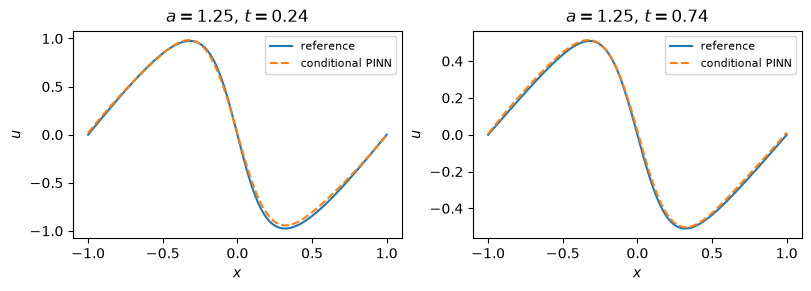

In [12]:
# C: parameterized PINN with input columns [x, t, a].
def make_conditional_net(width=32):
    """Condition on one scalar amplitude in addition to space and time."""
    return nn.Sequential(nn.Linear(3, width), nn.Tanh(),
                         nn.Linear(width, width), nn.Tanh(),
                         nn.Linear(width, 1))


def conditional_residual(model, xta, nu=NU_TRUE):
    """Burgers PDE differentiates x/t only; amplitude is a parameter."""
    xta = xta.detach().clone().requires_grad_(True)
    u = model(xta)
    first = grad(u, xta)
    u_x, u_t = first[:, :1], first[:, 1:2]
    u_xx = grad(u_x, xta)[:, :1]
    return u_t + u*u_x - nu*u_xx


def conditional_losses(model, n_f=256, n_i=80, n_b=80):
    """Apply PDE, initial and boundary constraints at random amplitudes."""
    xt_f, xt_i, xt_b = sample_sets(n_f=n_f, n_i=n_i, n_b=n_b)
    # Sample independent amplitudes for PDE, initial and boundary points.
    af = 0.5 + torch.rand(len(xt_f), 1)
    ai = 0.5 + torch.rand(len(xt_i), 1)
    ab = 0.5 + torch.rand(len(xt_b), 1)
    lf = conditional_residual(model, torch.cat([xt_f, af], dim=1)).square().mean()
    ui_target = -ai*torch.sin(PI*xt_i[:, :1])
    li = (model(torch.cat([xt_i, ai], dim=1)) - ui_target).square().mean()
    lb = model(torch.cat([xt_b, ab], dim=1)).square().mean()
    return lf + 10*li + 10*lb, (lf, li, lb)

# Three-input automatic differentiation formula sanity check.
class CondPoly(nn.Module):
    def forward(self, xta):
        return xta[:, :1]**2 * (xta[:, 1:2]+1)*xta[:, 2:3]

probe_cond = torch.tensor([[0.2, 0.5, 1.2], [-0.7, 0.3, 0.8]])
xp, tp, ap = probe_cond[:, :1], probe_cond[:, 1:2], probe_cond[:, 2:3]
up = xp*xp*(tp+1)*ap
expected_cond = xp*xp*ap + up*(2*xp*(tp+1)*ap) - NU_TRUE*(2*(tp+1)*ap)
assert torch.allclose(conditional_residual(CondPoly(), probe_cond), expected_cond,
                      atol=1e-5)

torch.manual_seed(102)
conditional_model = make_conditional_net()
opt_cond = torch.optim.Adam(conditional_model.parameters(), lr=2e-3)
conditional_history = []
for k in range(3000):
    opt_cond.zero_grad()
    loss_cond, cond_parts = conditional_losses(conditional_model)
    loss_cond.backward()
    opt_cond.step()
    if k % 50 == 0:
        conditional_history.append([k, *[q.detach().item() for q in cond_parts]])

# Hold out one particular amplitude inside the training range.
a_test = 1.25
x_cond, t_cond, U_cond_ref = burgers_reference(nu=NU_TRUE, amplitude=a_test)
t_mesh, x_mesh = np.meshgrid(t_cond, x_cond, indexing='ij')
query_cond = torch.tensor(np.c_[x_mesh.ravel(), t_mesh.ravel(),
                                np.full(x_mesh.size, a_test)], dtype=torch.float32)
with torch.no_grad():
    U_cond_pinn = conditional_model(query_cond).numpy().reshape(len(t_cond),len(x_cond))
cond_rel_error = relative_error(U_cond_pinn, U_cond_ref)
print(f'Conditional PINN: a={a_test:.2f} (in-family, held-out value), '
      f'relative state error={cond_rel_error:.3e}')

fig, axs = plt.subplots(1, 2, figsize=(8.0, 2.8), constrained_layout=True)
for time_target in (0.25, 0.75):
    ix = np.argmin(np.abs(t_cond-time_target))
    axis = axs[0] if time_target == 0.25 else axs[1]
    axis.plot(x_cond, U_cond_ref[ix], label='reference')
    axis.plot(x_cond, U_cond_pinn[ix], '--', label='conditional PINN')
    axis.set(title=f'$a={a_test:.2f}$, $t={t_cond[ix]:.2f}$', xlabel='$x$', ylabel='$u$')
    axis.legend(fontsize=8)
plt.show()

**Interpretation.** A conditional PINN receives $a$ as part of its input and enforces the PDE and its initial/boundary conditions over a *distribution of amplitudes*. It can therefore represent a family of solutions with a finite-dimensional parameterization. Its errors are an empirical test of interpolation within that family, not a guarantee of accuracy at other amplitudes or arbitrary initial profiles. General operator learning accepts function-valued inputs (often encoded by sensors, branch networks or Fourier-space representations), rather than assuming every initial profile is described by one scalar.

#### Bonus D — Can a PINN overfit its physics collocation points?

**Hypothesis.** Minimizing the PDE residual on only a few fixed collocation coordinates may leave large residuals elsewhere. We compare fixed points with resampling, using the same architecture, network initialization, number of collocation points per step, and optimization budget. A poor result is possible but not guaranteed in every run; the held-out residual is the relevant diagnostic.

Fixed: MSE at 12 fixed points=1.87e-04, MSE on dense grid=4.48e-01, state rel error=4.206e-01
Resampled: MSE at 12 fixed points=7.07e-03, MSE on dense grid=1.12e-02, state rel error=1.931e-02


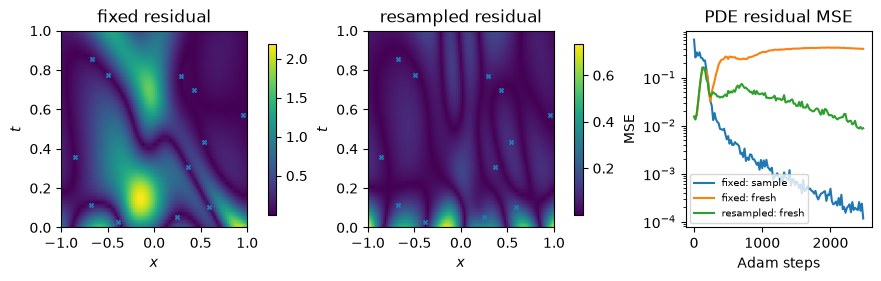

In [13]:
# D: 12 PDE points, fixed vs independently resampled each iteration.
d_rng = torch.Generator().manual_seed(901)
fixed_coords = torch.cat([2*torch.rand(12,1,generator=d_rng)-1,
                          torch.rand(12,1,generator=d_rng)], dim=1)

# Use the same initialization for both experiments.
torch.manual_seed(901)
fixed_net = make_burgers_net()
torch.manual_seed(901)
resampled_net = make_burgers_net()

d_steps = 2500
fixed_hist, _ = train_burgers(fixed_net, steps=d_steps, n_f=12, fixed_f=fixed_coords)
resamp_hist, _ = train_burgers(resampled_net, steps=d_steps, n_f=12, fixed_f=None)

fixed_r = residual_map(fixed_net, burgers_residual, NU_TRUE, x_ref, t_ref)
resamp_r = residual_map(resampled_net, burgers_residual, NU_TRUE, x_ref, t_ref)
def report_sampling(label, model, map_r):
    training_mse = burgers_residual(model, fixed_coords, NU_TRUE).square().mean().item()
    holdout_mse = float(np.mean(map_r**2))
    state_err = relative_error(predict_on_grid(model, x_ref, t_ref), U_ref)
    print(f'{label}: MSE at 12 fixed points={training_mse:.2e}, '
          f'MSE on dense grid={holdout_mse:.2e}, state rel error={state_err:.3e}')

report_sampling('Fixed', fixed_net, fixed_r)
report_sampling('Resampled', resampled_net, resamp_r)

fig, axs = plt.subplots(1, 3, figsize=(8.7, 2.7), constrained_layout=True)
for ax, arr, label in ((axs[0], fixed_r, 'fixed residual'),
                       (axs[1], resamp_r, 'resampled residual')):
    im = ax.imshow(np.abs(arr), extent=(x_ref[0],x_ref[-1],t_ref[0],t_ref[-1]),
                   origin='lower', aspect='auto')
    ax.scatter(fixed_coords[:,0], fixed_coords[:,1], s=9, marker='x')
    ax.set(title=label, xlabel='$x$', ylabel='$t$')
    fig.colorbar(im, ax=ax, fraction=0.046)
axs[2].semilogy(fixed_hist[:,0], np.maximum(fixed_hist[:,3],1e-12), label='fixed: sample')
axs[2].semilogy(fixed_hist[:,0], np.maximum(fixed_hist[:,5],1e-12), label='fixed: fresh')
axs[2].semilogy(resamp_hist[:,0], np.maximum(resamp_hist[:,5],1e-12), label='resampled: fresh')
axs[2].set(title='PDE residual MSE', xlabel='Adam steps', ylabel='MSE')
axs[2].legend(fontsize=7)
plt.show()

**Interpretation.** The finite set of collocation points is itself a sampling choice. Fixed-point optimization can drive the residual close to zero at the coordinates it sees while leaving much larger residuals in unobserved regions. Repeated resampling spreads physics information over the domain and can reduce this gap, but the effect depends on optimization budget, number and placement of samples, and network capacity. The overlaid markers are the twelve fixed coordinates; for the resampled network they are comparison locations only, not its entire changing training set. A grid residual tests PDE satisfaction, while reference state error tests actual solution fidelity.

#### Bonus E — Time extrapolation (extra diagnostic)

The main exercise validates on $t\in[0,1]$. To test $t\in[1,1.5]$, recompute the numerical reference *and* evaluate the network on those new coordinates. In contrast with a changed initial condition, this keeps the physical problem fixed and changes the queried time horizon.

Extrapolation: t<=1 rel error 1.817e-02
Extrapolation: 1<t<=1.5 rel error 1.258e-01


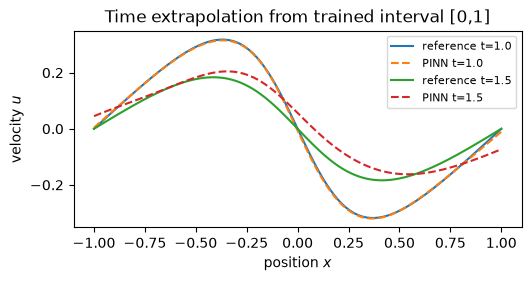

In [14]:
# E: honest matching-grid extrapolation experiment.
x_ext, t_ext, U_ext = burgers_reference(nu=NU_TRUE, nx=101, nt=76, t_f=1.5)
U_ext_pinn = predict_on_grid(forward_model, x_ext, t_ext)
in_domain = t_ext <= 1.0 + 1e-12
beyond = t_ext > 1.0 + 1e-12
print('Extrapolation: t<=1 rel error',
      f'{relative_error(U_ext_pinn[in_domain], U_ext[in_domain]):.3e}')
print('Extrapolation: 1<t<=1.5 rel error',
      f'{relative_error(U_ext_pinn[beyond], U_ext[beyond]):.3e}')
fig, ax = plt.subplots(figsize=(5.2, 2.7), constrained_layout=True)
for sample_t in (1.0, 1.5):
    ti = np.argmin(np.abs(t_ext - sample_t))
    ax.plot(x_ext, U_ext[ti], label=f'reference t={t_ext[ti]:.1f}')
    ax.plot(x_ext, U_ext_pinn[ti], '--', label=f'PINN t={t_ext[ti]:.1f}')
ax.set(title='Time extrapolation from trained interval [0,1]',
       xlabel='position $x$', ylabel='velocity $u$')
ax.legend(fontsize=8)
plt.show()

**Interpretation.** An ordinary PINN approximates a field on the region where its residual and constraints were enforced; nothing in the empirical training objective guarantees accurate predictions beyond that time interval. This test is distinct from the changed-initial-condition experiment: the PDE instance remains unchanged but the evaluation domain extends. The reported errors quantify what happened *for this trained network* only.

### What have you learned

1. Which parts of Burgers' equation, initial condition and boundary conditions entered your loss?
2. Where was the largest forward error or residual, and what did the numerical reference show?
3. What viscosity did you recover, from how many (noisy) measurements, and how confidently would you interpret that estimate?
4. Why did the unchanged PINN fail the new-initial-condition test?

#### References
- M. Raissi, P. Perdikaris and G. E. Karniadakis, [*Physics-informed neural networks: A deep learning framework for solving forward and inverse problems involving nonlinear partial differential equations*](https://doi.org/10.1016/j.jcp.2018.10.045), *Journal of Computational Physics* 378 (2019), 686–707.